# MedAgent: 01. Medical Signal Exploration & Filtering
## Interactive Analysis of Raw Electrocardiogram (ECG) Signals

This notebook explores physiological signal processing for the **MIT-BIH Arrhythmia Database**:
1. Loading raw continuous records via WFDB (`100.dat`, `100.hea`, `100.atr`).
2. Frequency domain analysis using Fast Fourier Transform (FFT) and Power Spectral Density (PSD).
3. Zero-phase Butterworth Bandpass Filtering ($0.5 - 45\text{ Hz}$) to remove baseline wander and EMG noise.
4. IIR Notch Filtering ($60\text{ Hz}$) to attenuate AC mains interference.
5. Signal visualization and signal-to-noise ratio (SNR) comparison.

In [1]:
import sys
from pathlib import Path

# Robust project root determination whether cwd is MedAgent or MedAgent/notebooks
current_dir = Path.cwd().resolve()
if (current_dir / "src").exists():
    PROJECT_ROOT = current_dir
elif (current_dir.parent / "src").exists():
    PROJECT_ROOT = current_dir.parent
else:
    PROJECT_ROOT = current_dir

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

# Ensure venv site-packages are accessible even if run from a generic kernel
VENV_SITE = PROJECT_ROOT / "venv" / "Lib" / "site-packages"
if VENV_SITE.exists() and str(VENV_SITE) not in sys.path:
    sys.path.insert(0, str(VENV_SITE))

import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
import wfdb

from src.data.preprocessing.ecg_cleaner import (
    apply_bandpass_filter,
    apply_notch_filter,
    clean_ecg,
    normalize_signal
)

print(f"Project root: {PROJECT_ROOT}")
print("WFDB and signal processing packages successfully imported!")

Project root: C:\Users\tewod\Desktop\projects\MedAgent
WFDB and signal processing packages successfully imported!


### 1. Load Raw MIT-BIH Arrhythmia Record
Let's load Record `100` from `data/raw/ecg/mit-bih-arrhythmia-database-1.0.0/`.

In [2]:
record_path = PROJECT_ROOT / "data" / "raw" / "ecg" / "mit-bih-arrhythmia-database-1.0.0" / "100"
record = wfdb.rdrecord(str(record_path))
annotation = wfdb.rdann(str(record_path), "atr")

fs = float(record.fs)
signal_names = record.sig_name
ecg_raw = record.p_signal[:, 0]  # First lead (MLII)
time_vec = np.arange(len(ecg_raw)) / fs

print(f"Sampling Rate: {fs} Hz")
print(f"Signal Length: {len(ecg_raw)} samples ({len(ecg_raw)/fs:.1f} seconds)")
print(f"Available Leads: {signal_names}")
print(f"Total Annotations: {len(annotation.sample)}")

Sampling Rate: 360.0 Hz
Signal Length: 650000 samples (1805.6 seconds)
Available Leads: ['MLII', 'V5']
Total Annotations: 2274


### 2. Time-Domain Visualization of Raw ECG
Let's inspect a 10-second segment of the raw ECG signal.

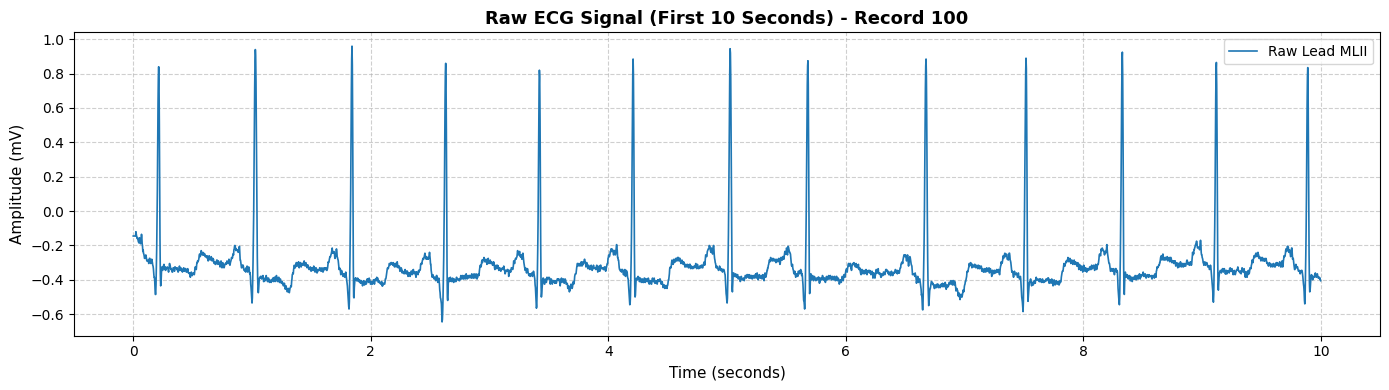

In [3]:
segment_sec = 10
segment_samples = int(segment_sec * fs)

plt.figure(figsize=(14, 4))
plt.plot(time_vec[:segment_samples], ecg_raw[:segment_samples], color="#1f77b4", lw=1.2, label="Raw Lead MLII")
plt.title(f"Raw ECG Signal (First {segment_sec} Seconds) - Record 100", fontsize=13, fontweight="bold")
plt.xlabel("Time (seconds)", fontsize=11)
plt.ylabel("Amplitude (mV)", fontsize=11)
plt.grid(True, linestyle="--", alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()

### 3. Frequency Spectrum Analysis (FFT & PSD)
Biomedical ECG information is primarily concentrated in the **$0.5\text{ Hz} - 45\text{ Hz}$** range:
- **Baseline Wander (Respiration, Motion)**: $< 0.5\text{ Hz}$
- **Powerline Interference**: $60\text{ Hz}$ (or $50\text{ Hz}$)
- **High-Frequency Muscle Noise (EMG)**: $> 50\text{ Hz}$

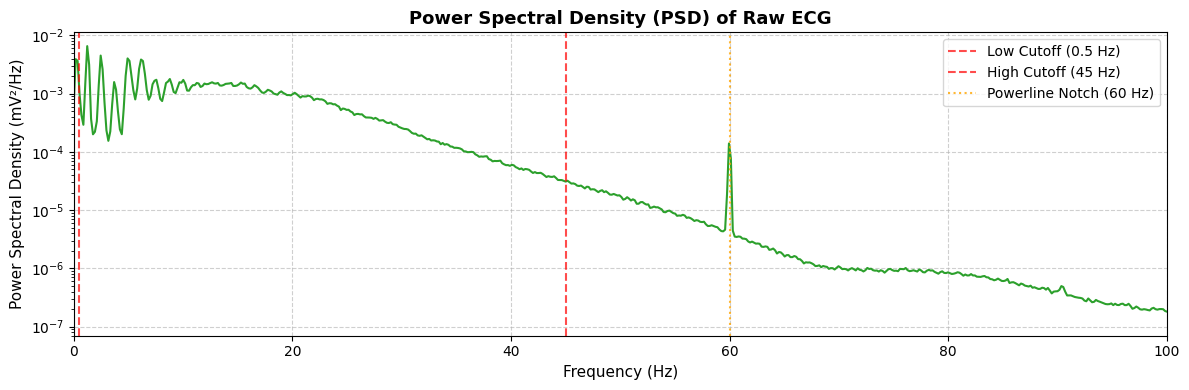

In [4]:
freqs, psd = signal.welch(ecg_raw, fs=fs, nperseg=2048)

plt.figure(figsize=(12, 4))
plt.semilogy(freqs, psd, color="#2ca02c", lw=1.5)
plt.axvline(0.5, color="red", linestyle="--", alpha=0.7, label="Low Cutoff (0.5 Hz)")
plt.axvline(45.0, color="red", linestyle="--", alpha=0.7, label="High Cutoff (45 Hz)")
plt.axvline(60.0, color="orange", linestyle=":", alpha=0.8, label="Powerline Notch (60 Hz)")
plt.title("Power Spectral Density (PSD) of Raw ECG", fontsize=13, fontweight="bold")
plt.xlabel("Frequency (Hz)", fontsize=11)
plt.ylabel("Power Spectral Density (mV²/Hz)", fontsize=11)
plt.xlim(0, 100)
plt.grid(True, linestyle="--", alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()

### 4. Step-by-Step Digital Filtering
Let's filter the raw ECG with:
1. **Butterworth Bandpass Filter** ($0.5 - 45\text{ Hz}$, 4th order, zero-phase)
2. **IIR Notch Filter** ($60\text{ Hz}$, $Q=30$)
3. **Z-Score Normalization**

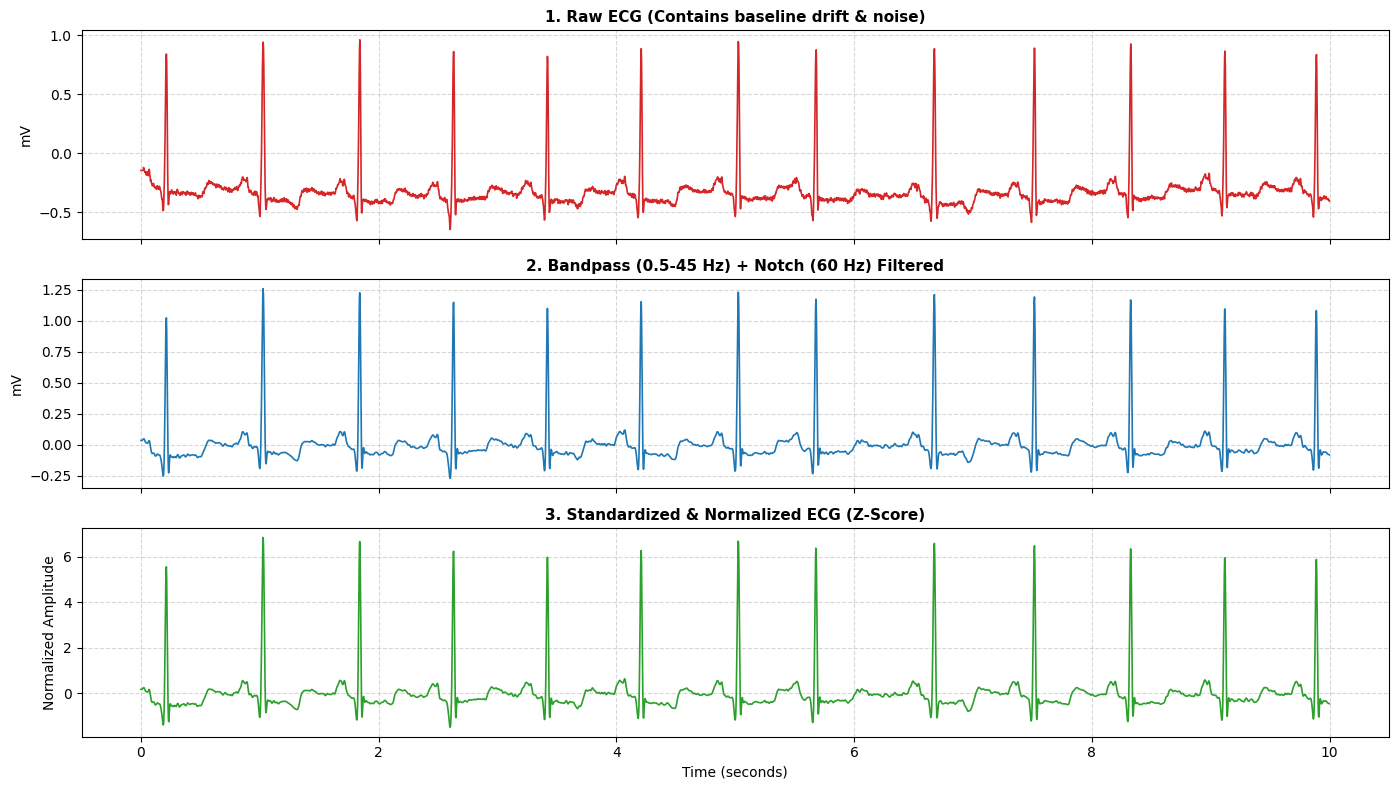

In [5]:
# 1. Bandpass filter
ecg_bandpassed = apply_bandpass_filter(ecg_raw, sampling_rate=fs, lowcut=0.5, highcut=45.0, order=4)

# 2. Notch filter
ecg_notched = apply_notch_filter(ecg_bandpassed, sampling_rate=fs, notch_freq=60.0)

# 3. End-to-end cleaned & normalized
ecg_clean = clean_ecg(ecg_raw, sampling_rate=fs, lowcut=0.5, highcut=45.0, notch_freq=60.0, normalize=True)

# Plot comparison
fig, axes = plt.subplots(3, 1, figsize=(14, 8), sharex=True)

axes[0].plot(time_vec[:segment_samples], ecg_raw[:segment_samples], color="#d62728", lw=1.2)
axes[0].set_title("1. Raw ECG (Contains baseline drift & noise)", fontsize=11, fontweight="bold")
axes[0].set_ylabel("mV")
axes[0].grid(True, linestyle="--", alpha=0.5)

axes[1].plot(time_vec[:segment_samples], ecg_notched[:segment_samples], color="#1f77b4", lw=1.2)
axes[1].set_title("2. Bandpass (0.5-45 Hz) + Notch (60 Hz) Filtered", fontsize=11, fontweight="bold")
axes[1].set_ylabel("mV")
axes[1].grid(True, linestyle="--", alpha=0.5)

axes[2].plot(time_vec[:segment_samples], ecg_clean[:segment_samples], color="#2ca02c", lw=1.2)
axes[2].set_title("3. Standardized & Normalized ECG (Z-Score)", fontsize=11, fontweight="bold")
axes[2].set_xlabel("Time (seconds)")
axes[2].set_ylabel("Normalized Amplitude")
axes[2].grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

### 5. Overlay Comparison & R-Peak Alignment
We can overlay the annotated R-peak locations onto the cleaned waveform.

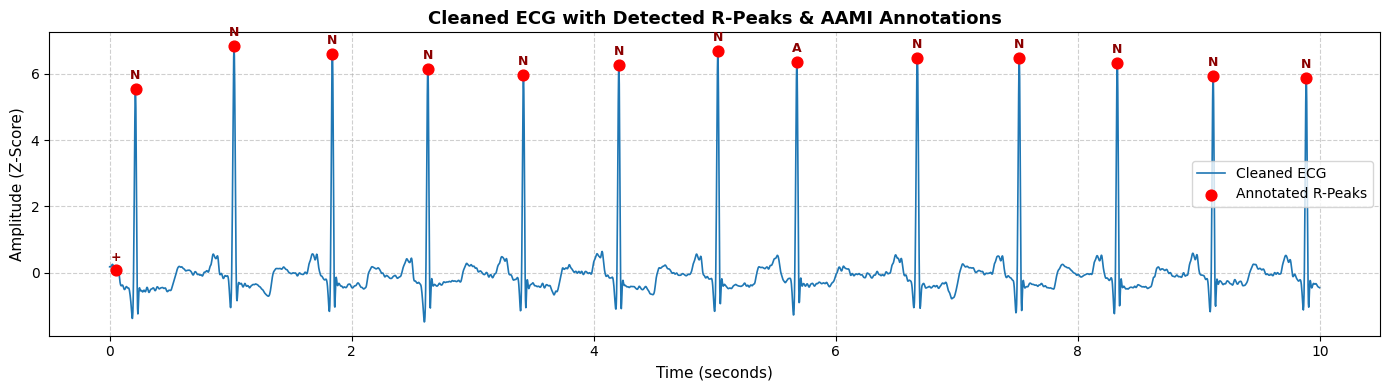

In [6]:
peaks_in_segment = [p for p in annotation.sample if p < segment_samples]
peak_times = np.array(peaks_in_segment) / fs
peak_amplitudes = ecg_clean[peaks_in_segment]

plt.figure(figsize=(14, 4))
plt.plot(time_vec[:segment_samples], ecg_clean[:segment_samples], color="#1f77b4", lw=1.2, label="Cleaned ECG")
plt.scatter(peak_times, peak_amplitudes, color="red", s=60, zorder=5, label="Annotated R-Peaks")

for t, a, sym in zip(peak_times, peak_amplitudes, [annotation.symbol[i] for i in range(len(peaks_in_segment))]):
    plt.annotate(sym, (t, a + 0.3), ha="center", fontsize=9, fontweight="bold", color="darkred")

plt.title("Cleaned ECG with Detected R-Peaks & AAMI Annotations", fontsize=13, fontweight="bold")
plt.xlabel("Time (seconds)", fontsize=11)
plt.ylabel("Amplitude (Z-Score)", fontsize=11)
plt.legend()
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()